# 03 — Feature engineering

**Phase 6 of Energy Intelligence.** No model is trained here.

## What are we doing?

We turn cleaned hourly load + Madrid weather into a table the model can use: one row per hour we want to predict.

## Why?

A model cannot see “yesterday” unless we give it yesterday as a column. If we build those columns carelessly, we leak the answer (the load we are trying to predict) into the inputs.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd

def project_root() -> Path:
    here = Path.cwd()
    for candidate in (here, here.parent):
        if (candidate / "data" / "processed" / "spain_hourly_features.csv").exists():
            return candidate
    raise FileNotFoundError("Run: python ml_pipeline/build_features.py")

ROOT = project_root()
features = pd.read_csv(ROOT / "data" / "processed" / "spain_hourly_features.csv")
metadata = json.loads((ROOT / "data" / "processed" / "feature_list.json").read_text(encoding="utf-8"))
print(f"Rows: {len(features):,}")
print("Target:", metadata["target"])
print("Features:", metadata["features"])
print("Weather timing:", metadata["weather_timing"])
features.head(3)

Rows: 50,014
Target: load_mw
Features: ['hour', 'day_of_week', 'month', 'is_weekend', 'lag_1', 'lag_24', 'lag_168', 'rolling_mean_24', 'rolling_mean_168', 'temperature_c', 'relative_humidity_pct', 'wind_speed_kmh']
Weather timing: lag_1 — last known Madrid hour, not observed weather at t


,utc_timestamp,local_timestamp,load_mw,hour,day_of_week,month,is_weekend,lag_1,lag_24,lag_168,rolling_mean_24,rolling_mean_168,temperature_c,relative_humidity_pct,wind_speed_kmh
0,2015-01-09T19:00:00Z,2015-01-09T20:00:00+0100,36925.0,20,4,1,0,36887.0,38551.0,33955.0,32446.541667,29082.279762,8.8,70.0,1.6
1,2015-01-09T20:00:00Z,2015-01-09T21:00:00+0100,36185.0,21,4,1,0,36925.0,37640.0,33851.0,32378.791667,29099.958333,7.8,71.0,4.7
2,2015-01-09T21:00:00Z,2015-01-09T22:00:00+0100,34169.0,22,4,1,0,36185.0,34828.0,32324.0,32318.166667,29113.851190,4.5,83.0,5.9


## Row definition

Each row is hour **t**, the hour we want to forecast.

| Column | When it is known |
| --- | --- |
| `load_mw` | **After** hour t. This is the **target**, not an input. |
| `hour`, `day_of_week`, `month`, `is_weekend` | Before hour t. The calendar is known. |
| `lag_1` | Load at t−1 (the most recent observation). |
| `lag_24` / `lag_168` | Same hour yesterday / last week. |
| `rolling_mean_24` / `rolling_mean_168` | Mean of past hours **ending at t−1**. |
| `temperature_c`, humidity, wind | Madrid weather at **t−1**, not observed weather at t. |

That last point matters. Using the actual temperature at t would assume a perfect next-hour weather forecast. We stay conservative: last known weather only.

## Why these features (from EDA, not from wishful thinking)

| Feature | Why it may help |
| --- | --- |
| `hour` | Double daily peak (midday and ~21:00). |
| `day_of_week` / `is_weekend` | Sunday load is much lower than Wednesday. |
| `month` | Winter heating and July cooling. |
| `lag_1` | Demand barely jumps in one hour. Persistence will be a strong baseline. |
| `lag_24` | Daily seasonality. |
| `lag_168` | Weekly seasonality. |
| rolling means | Recent *level* of demand (heat wave week vs holiday week). |
| weather | Heating/cooling. Linear correlation can look weak because both cold and hot hours raise load. |

We did **not** add ENTSO-E’s official forecast, wind generation, or holidays. Generation is supply. The official forecast would make our model less independent.

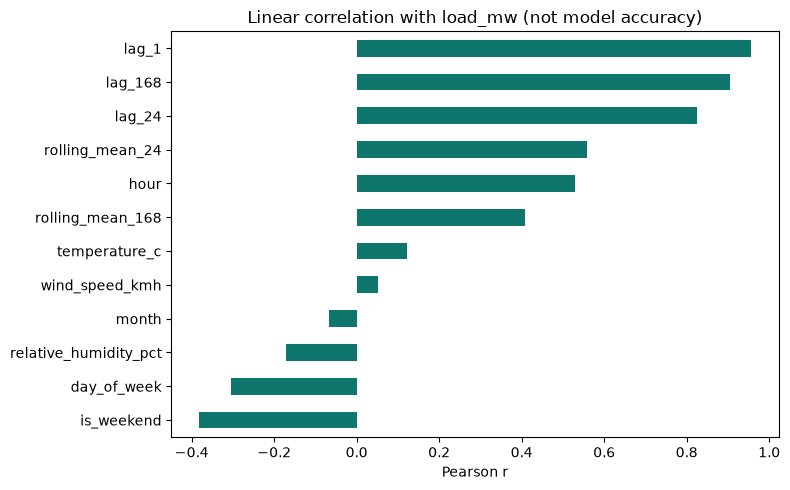

is_weekend              -0.382
day_of_week             -0.304
relative_humidity_pct   -0.171
month                   -0.068
wind_speed_kmh           0.053
temperature_c            0.121
rolling_mean_168         0.408
hour                     0.528
rolling_mean_24          0.558
lag_24                   0.825
lag_168                  0.905
lag_1                    0.956
dtype: float64


In [2]:
feature_cols = metadata["features"]
corr = features[feature_cols].corrwith(features["load_mw"]).sort_values()
ax = corr.plot(kind="barh", color="#0f766e", figsize=(8, 5))
ax.set_title("Linear correlation with load_mw (not model accuracy)")
ax.set_xlabel("Pearson r")
plt.tight_layout()
plt.show()
print(corr.round(3))

### What this means

`lag_1` dominates (~0.96). That is a **data fact**, not a trained score. A model that only copies last hour will already be hard to beat on MAE. `is_weekend` is negative: weekends use less electricity. `temperature_c` is only weakly linear; a U-shape (cold and hot) can hide inside a small Pearson r.

**What could go wrong:** treating these correlations as “the model is 96% accurate.” They are not accuracy.

## Leakage check

In [3]:
# rolling_mean_24 must not equal the target and should be close to
# the mean of the previous 24 lag-aligned hours on a quiet stretch.
sample = features.iloc[200]
print("target load_mw     ", sample["load_mw"])
print("lag_1              ", sample["lag_1"])
print("rolling_mean_24    ", round(sample["rolling_mean_24"], 2))
print("target == lag_1?   ", sample["load_mw"] == sample["lag_1"])
print("Calendar hour      ", int(sample["hour"]), " weekend=", int(sample["is_weekend"]))

target load_mw      21973.0
lag_1               22446.0
rolling_mean_24     28925.5
target == lag_1?    False
Calendar hour       4  weekend= 1


## Files used later

- `data/processed/spain_hourly_features.csv` — training table
- `data/processed/feature_list.json` — target name + feature order

Training (next phase) must split **by time**, not shuffle these rows.

Phase 6 stops here. No Linear Regression, no XGBoost, no saved `.joblib` yet.